# 5장 · CSV 읽기와 데이터 정제

CSV의 열을 읽으면 숫자처럼 보이는 값도 문자열일 수 있습니다. 변환할 열과 누락으로 처리할 값을 먼저 정하면 정제 결과를 다시 확인할 수 있습니다.

기록표를 받았는데 id가 2인 첫 행은 시간이 비어 있고 그다음 행에는 20분이 적혀 있습니다. 중복부터 지우면 쓸 수 있는 20분이 사라집니다. 어느 행을 먼저 남길지 작은 표로 확인합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 pandas 2.2.3입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## csv.DictReader와 문자열 필드

이 CSV에서는 쉼표가 한 줄 안의 칸을 나누고 줄바꿈이 행을 나눕니다. 노트북에 넣은 여섯 줄은 예제 records.csv와 같습니다. StringIO로 파일처럼 열어 보므로 경로를 설정할 필요가 없습니다.


### 셀 01 · csv.DictReader로 행 읽기

둘째 데이터 행에서 minutes를 꺼내 보세요. 빈 문자열은 화면에 잘 안 보이므로 repr로 표시합니다.


In [1]:
import csv
from io import StringIO
csv_text = """id,title,minutes
1,  Python   기초  ,30
2,Git 연습,
2,Git 연습,20
3,,15
4,CSV  읽기,40
4,CSV  읽기,40
"""
rows = list(csv.DictReader(StringIO(csv_text)))
print(repr(rows[1]["minutes"]))

''


작은따옴표 두 개는 길이 0인 문자열입니다. 0분이라는 뜻으로 고치면 누락된 값과 실제 0분을 구분할 수 없습니다.


### CSV·JSON 직렬화와 역직렬화

<p>CSV는 쉼표 같은 구분자로 열을 나누는 표 형식입니다. 값 안에도 쉼표가 있을 수 있어 문자열을 split(",")으로 자르지 않고 csv 모듈을 사용합니다. DictReader는 첫 행을 키로 삼아 각 행을 딕셔너리로 읽습니다. 여기서 분 값 "30"도 문자열입니다.</p>

<p>with 블록은 파일을 사용한 뒤 닫는 처리를 맡습니다. newline=""는 csv 모듈이 줄바꿈을 처리하도록 하는 옵션입니다. list(...)는 행을 읽어 작은 목록으로 모읍니다.</p>

<p>JSON은 표 외에도 중첩 목록·객체를 담을 수 있습니다. 이번에는 CSV 행 목록을 JSON으로 바꾸고 다시 읽어 값이 같은지 확인합니다. json.dumps와 loads는 문자열을 처리하고, 실제 파일 읽기·쓰기는 Path 메서드가 맡습니다.</p>


### 셀 02 · split()과 join()으로 열 정제

첫 행 제목 사이에 공백이 몇 칸 있는지 눈으로 세지 않고 단어를 다시 잇습니다.


In [2]:
print(" ".join(rows[0]["title"].split()))

Python 기초


Python 기초가 됩니다. id는 행을 다시 찾을 때 쓸 이름이므로 제목 옆에 남겨 둡니다.


### 정수 변환과 유효한 행의 조건

<p>clean_row는 먼저 제목의 공백을 정리하고 minutes를 int로 바꿉니다. 시간이 빈 문자열이면 변환에서 ValueError가 나서 None을 반환합니다. 정수로 바뀌었더라도 제목이 없거나 시간이 0~480 밖이면 결과에 넣지 않습니다.</p>


## 결측 행 필터링과 ID 중복 제거

시간이 비었거나 제목이 비면 그 행은 보류합니다. 이 표의 시간은 0~480 사이의 정수만 허용합니다. 남은 행 안에 같은 id가 다시 나타나면 먼저 본 유효 행을 씁니다.

<!-- lesson-visual visual-clean-order -->
**어떤 2번 행을 남길까요?**

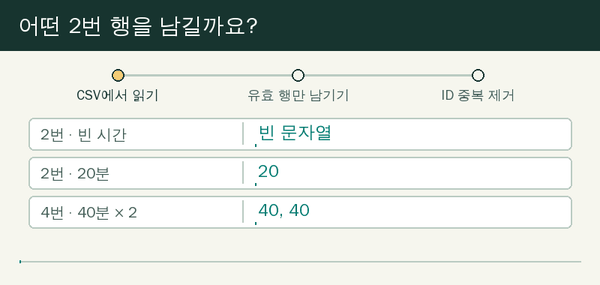

minutes가 빈 첫 2번 행을 먼저 제외합니다. 유효한 행만 모은 뒤 ID를 비교해야 20분짜리 2번 행이 남습니다.
<!-- /lesson-visual visual-clean-order -->


### 셀 03 · 유효한 행만 리스트에 추가

아래 함수는 이 작은 CSV의 정수 표기만 읽습니다. 숫자 변환과 범위 검사까지 성공한 행을 모으세요.

CSV의 minutes는 문자열입니다. clean_row는 '30'을 30으로 바꾸지만 '30.0'에서는 int 변환이 실패해 행을 제외합니다. 뒤의 판다스 예시는 먼저 숫자로 읽어 정수와 값이 같은 30.0을 허용합니다. 팀 자료에는 어느 표기까지 허용할지 한 가지 규칙을 정하세요.


In [3]:
def clean_row(row):
    title = " ".join(row["title"].split())
    try:
        minutes = int(row["minutes"])
    except ValueError:
        return None
    if not row["id"].strip() or not title or not 0 <= minutes <= 480:
        return None
    return {"id": row["id"].strip(), "title": title, "minutes": minutes}

valid = []
for row in rows:
    cleaned = clean_row(row)
    if cleaned is not None:
        valid.append(cleaned)
print([row["id"] for row in valid])

['1', '2', '4', '4']


1, 2, 4, 4가 남습니다. 먼저 나타난 2번 행은 시간이 없어서 빠졌고 3번은 제목이 비었습니다. 4번 두 건은 내용이 유효하므로 아직 둘 다 있습니다.


### 유효성 검사와 중복 제거 순서

<p>같은 id의 내용이 다르면 어느 것을 남길지 업무 규칙이 필요합니다. 여기서는 유효한 행 중 첫 행을 남긴다는 규칙을 명시했습니다. 모든 실제 데이터에 적용할 정답은 아닙니다.</p>

<p>drop_duplicates는 subset에 적은 열을 비교합니다. keep="first"는 현재 순서에서 첫 행을 남깁니다. 중복 제거를 먼저 하면 누락 시간의 id=2가 남고 유효한 20분 기록을 잃을 수 있습니다.</p>

<p>return cleaned, report는 두 값을 함께 반환합니다. 호출자는 cleaned, report = clean_table(frame)처럼 두 이름에 나누어 받습니다. 반환한 표와 보고서를 함께 확인하세요.</p>

<h3>6행이 3행으로 정리되는 과정</h3>

<p>누락 제거와 중복 제거의 순서를 눈으로 추적합니다.</p>

<article><small>STEP 01 · CSV</small><h4>CSV 입력 행 수</h4>
<p>id=2와 id=4가 각각 두 번 있습니다.</p><pre>before = 6</pre></article>

<article><small>STEP 02 · 조건 필터</small><h4>유효성 검사에서 제외한 행</h4>
<p>분이 빈 id=2 한 행, 제목이 빈 id=3 한 행을 제외합니다.</p><pre>유효 ID: [1, 2, 4, 4]</pre></article>

<article><small>STEP 03 · id 기준</small><h4>ID 중복 제거</h4>
<p>유효한 id=4 중 첫 행을 유지합니다.</p><pre>첫 4는 유지 · 두 번째 4 제외
남은 ID: [1, 2, 4]</pre></article>

<article><small>STEP 04 · 출력</small><h4>정제 후 남은 행</h4>
<p>앞의 JSON 저장 연습은 한 행을 사용합니다. 여기에 나온 세 행은 전체 표를 정리한 결과입니다.</p><pre>전체 표: 3행, 합계 90분</pre></article>


### 과제 04 · ID별 첫 행 보존

사전 by_id에 아직 없는 id만 저장하고 남은 기록의 시간을 출력하세요.


In [4]:
by_id = {}
# valid에서 첫 유효 행을 id별로 모으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>by_id = {}
for row in valid:
    if row[&quot;id&quot;] not in by_id:
        by_id[row[&quot;id&quot;]] = row
print([row[&quot;minutes&quot;] for row in by_id.values()])</code></pre>
<p>실행 결과</p><pre><code>[30, 20, 40]</code></pre>
<p>30, 20, 40이 남습니다. 입력 여섯 행 가운데 무효 두 행과 중복 한 행을 빼면 세 행입니다.</p>
</details>


### ID 중복을 언제 판정할까요?

<p>시간 칸이 빈 ID 2 행 뒤에 20분이 적힌 ID 2 행이 있습니다. 유효한 시간인지 먼저 검사하면 두 번째 행이 살아남습니다. 어느 순서에서 20분까지 사라지는지 두 행을 직접 따라가 보세요.</p>


## pandas의 결측값 판별

표 전체를 다룰 때는 Pandas의 DataFrame을 씁니다. 수업용 커널에 pandas가 있으면 아래 셀이 실제 열을 선택합니다. 설치되지 않은 환경에서도 앞의 CSV 실습은 그대로 동작합니다.


### 셀 05 · isna()로 결측값 검사

문자열로 읽은 뒤 숫자로 바꿀 수 없는 값을 결측값으로 표시합니다.


In [5]:
from importlib.util import find_spec
if find_spec("pandas") is not None:
    import pandas as pd
    frame = pd.read_csv(StringIO(csv_text), dtype=str, keep_default_na=False)
    minutes = pd.to_numeric(frame["minutes"], errors="coerce")
    print(minutes.isna().tolist())
else:
    print("이 커널에는 pandas가 없습니다. CSV의 두 번째 데이터 행에서 시간을 확인하세요.")

[False, True, False, False, False, False]


Pandas가 있으면 여섯 값 중 둘째만 True입니다. 이는 시간 칸만 검사한 결과라서 제목이 빈 행은 아직 골라내지 않았습니다. 전체 예제의 clean_table은 제목·범위·정수 조건을 합친 뒤 중복을 제거합니다.


### pandas 행·열 선택

<p>DataFrame은 행과 열로 구성한 표입니다. frame["id"]는 한 열인 Series를 선택하고, frame[["id", "minutes"]]는 여러 열을 가진 표를 선택합니다. frame.shape는 (행 수, 열 수)입니다.</p>

<p>read_csv에서 dtype=str로 읽어 id의 앞자리 0 같은 표시를 보존합니다. keep_default_na=False는 빈 칸과 NA 같은 글자를 처음에는 문자열 그대로 읽게 합니다. 누락을 어떻게 판정할지는 다음 단계에서 직접 정합니다.</p>

<p>frame["id"] == "2"는 각 행마다 참·거짓을 계산합니다. loc[행 조건, 열 목록]은 조건을 만족한 행과 지정한 열을 고릅니다. to_dict(orient="records")는 표를 행별 딕셔너리 목록으로 바꿉니다.</p>


## UTF-8 JSON 파일 쓰기와 읽기

메모리 안의 사전은 커널을 닫으면 사라집니다. 임시 폴더에 실제 파일을 저장하고 같은 인코딩으로 다시 열어 첫 유효 행의 값이 남았는지 확인합니다.


### 작업 디렉터리와 파일 경로

<p>Path는 경로를 다루는 객체입니다. / 연산으로 폴더·파일 이름을 연결하고 resolve()는 절대 경로로 정리하며 parent는 부모 폴더를 뜻합니다. mkdir(exist_ok=True)는 폴더가 이미 있어도 오류를 내지 않습니다.</p>

<p>인코딩은 글자를 바이트로 저장하고 읽는 규칙입니다. 파일을 읽을 때와 쓸 때 UTF-8을 명시합니다. .read_text는 파일 전체를 문자열로 읽으므로 이번처럼 작은 파일에 사용합니다. 원본 data를 덮어쓰지 않고 output에 결과를 씁니다.</p>


### 파일 처리 재실행과 복구

<table><caption>흔한 오류</caption><thead><tr><th scope="col">오류·증상</th><th scope="col">확인</th><th scope="col">조치</th></tr>
</thead><tbody><tr><td>FileNotFoundError</td><td>경로·입력 파일 존재</td><td>data 폴더 구조 복구</td></tr>
<tr><td>UnicodeDecodeError</td><td>실제 파일 인코딩</td><td>원본 인코딩 확인 후 지정</td></tr>
<tr><td>KeyError: title</td><td>열 이름·공백·BOM</td><td>열 이름 목록 출력 후 원본 확인</td></tr>
<tr><td>엉뚱한 Unnamed 열</td><td>CSV 저장 때 index 포함</td><td>index=False로 저장</td></tr>
<tr><td>누락 분이 0으로 바뀜</td><td>자동 채우기 규칙</td><td>제외·대체 정책을 먼저 정함</td></tr>
</tbody></table>


### 셀 06 · read_text()와 json.loads()로 복원

파일을 여는 기준 폴더와 이름을 Path로 합칩니다. 이번 입력은 valid의 첫 행이므로 앞 과제를 풀기 전에도 실행할 수 있습니다.


In [6]:
import json
from pathlib import Path
from tempfile import TemporaryDirectory

with TemporaryDirectory() as folder:
    target = Path(folder) / "record.json"
    target.write_text(json.dumps(valid[0], ensure_ascii=False), encoding="utf-8")
    restored = json.loads(target.read_text(encoding="utf-8"))
    print(restored["title"], restored["minutes"])

Python 기초 30


‘Python 기초 30’이 나옵니다. 글자를 쓸 때와 읽을 때 같은 UTF-8을 지정했고, loads를 거쳐 정수 시간도 되찾았습니다. 임시 폴더는 셀이 끝나면 정리됩니다.


### 같은 파일에서 UTF-8 JSON 복원

<p>문자열을 JSON으로 직렬화한 뒤 임시 폴더의 record.json에 씁니다. 같은 경로에서 다시 읽어 json.loads로 복원하면 첫 번째 유효 행의 ‘Python 기초’와 정수 30을 확인할 수 있습니다.</p>


## 돌아보기

처음 받은 CSV에서 특정 행을 지웠다면 이유를 말할 수 있어야 합니다. 2번 첫 행과 4번 마지막 행은 각각 다른 단계에서 빠집니다. 처리 결과를 JSON으로 저장할 때도 id와 정수 시간을 함께 남기면 원자료까지 돌아갈 수 있습니다.

### 6행이 3행으로 정리되는 과정

**6행을 읽음**　id=2와 id=4가 각각 두 번 있습니다.

```
before = 6
```

**잘못된 2행 제외**　분이 빈 id=2 한 행, 제목이 빈 id=3 한 행을 제외합니다.

```
유효 ID: [1, 2, 4, 4]
```

**중복 1행 제외**　유효한 id=4 중 첫 행을 유지합니다.

```
첫 4는 유지 · 두 번째 4 제외
남은 ID: [1, 2, 4]
```

**전체 표에서 남은 행**　앞의 JSON 저장 연습은 한 행을 사용합니다. 여기에 나온 세 행은 전체 표를 정리한 결과입니다.

```
전체 표: 3행, 합계 90분
```
